In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [14]:
def generate_streampulse_data(n_samples=5000, seed=42):
    rng = np.random.default_rng(seed)
    
    subscription_plan = rng.choice(['Basic', 'Standard', 'Premium'], size=n_samples, p=[0.45, 0.35, 0.20])
    contract_type = rng.choice(['Monthly', 'Annual'], size=n_samples, p=[0.72, 0.28])
    payment_method = rng.choice(['Credit Card', 'PayPal', 'Apple/Google Pay', 'Bank Transfer'], size=n_samples, p=[0.45, 0.25, 0.20, 0.10])
    device_type = rng.choice(['Smart TV', 'Mobile', 'Web', 'Console'], size=n_samples, p=[0.40, 0.30, 0.20, 0.10])
    
    tenure_months = rng.integers(1, 61, size=n_samples)
    weekly_watch_hours = np.round(rng.gamma(shape=2.5, scale=4.5, size=n_samples), 1)
    days_since_last_login = rng.exponential(scale=6.0, size=n_samples).astype(int)
    support_tickets = rng.poisson(lam=0.8, size=n_samples)
    failed_payments = rng.binomial(n=3, p=0.12, size=n_samples)
    avg_stream_quality_score = np.round(np.clip(rng.normal(4.2, 0.7, size=n_samples), 1.0, 5.0), 2)
    
    plan_prices = {'Basic': 8.99, 'Standard': 13.99, 'Premium': 18.99}
    monthly_fee = np.array([plan_prices[p] for p in subscription_plan])
    
    logit = (
        0.15
        + 0.95 * (contract_type == 'Monthly')
        - 0.035 * tenure_months
        - 0.08 * weekly_watch_hours
        + 0.09 * days_since_last_login
        + 0.55 * support_tickets
        + 0.85 * failed_payments
        - 0.45 * avg_stream_quality_score
        + 0.40 * (subscription_plan == 'Basic')
        + rng.normal(0, 0.5, size=n_samples)
    )
    prob_churn = 1 / (1 + np.exp(-logit))
    churn = rng.binomial(1, prob_churn)
    
    df = pd.DataFrame({
        'user_id': [f'SP_{100000 + i}' for i in range(n_samples)],
        'subscription_plan': subscription_plan,
        'contract_type': contract_type,
        'payment_method': payment_method,
        'device_type': device_type,
        'tenure_months': tenure_months,
        'monthly_fee': monthly_fee,
        'weekly_watch_hours': weekly_watch_hours,
        'days_since_last_login': days_since_last_login,
        'support_tickets': support_tickets,
        'failed_payments': failed_payments,
        'avg_stream_quality_score': avg_stream_quality_score,
        'churn': churn
    })

    for col in ['weekly_watch_hours', 'avg_stream_quality_score', 'device_type']:
        mask = rng.random(n_samples) < 0.04
        df.loc[mask, col] = np.nan
        
    return df

df = generate_streampulse_data(n_samples=5000, seed=RANDOM_STATE)
print(f'Розмір датасету: {df.shape}')
df.head()

Розмір датасету: (5000, 13)


,user_id,subscription_plan,contract_type,payment_method,device_type,tenure_months,monthly_fee,weekly_watch_hours,days_since_last_login,support_tickets,failed_payments,avg_stream_quality_score,churn
0,SP_100000,Standard,Monthly,Apple/Google Pay,Smart TV,55,13.99,14.2,12,1,1,4.60,0
1,SP_100001,Basic,Monthly,Apple/Google Pay,Smart TV,45,8.99,17.0,8,0,1,4.25,0
2,SP_100002,Premium,Annual,Credit Card,Smart TV,13,18.99,9.1,3,1,0,4.73,0
3,SP_100003,Standard,Monthly,Credit Card,Web,60,13.99,13.3,2,1,0,NaN,0
4,SP_100004,Basic,Monthly,Credit Card,NaN,60,8.99,1.7,13,0,1,4.22,0


--- Кількість пропусків по стовпцях ---
device_type                 209
weekly_watch_hours          196
avg_stream_quality_score    191
dtype: int64

--- Розподіл цільової змінної Churn (%) ---
churn
0    74.66
1    25.34
Name: proportion, dtype: float64


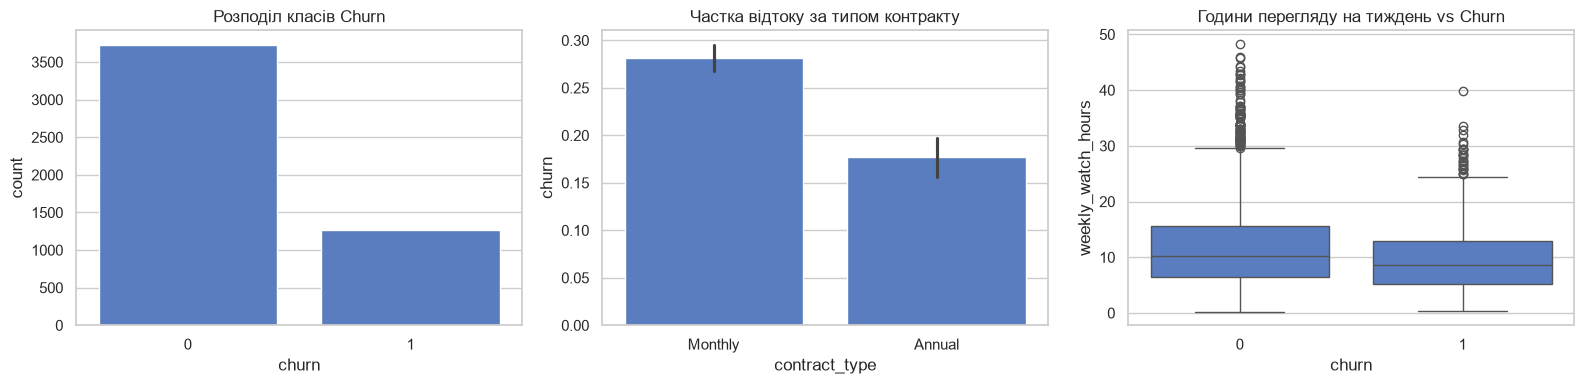

In [15]:
print('--- Кількість пропусків по стовпцях ---')
print(df.isnull().sum()[df.isnull().sum() > 0])

print('\n--- Розподіл цільової змінної Churn (%) ---')
print((df['churn'].value_counts(normalize=True) * 100).round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(data=df, x='churn', ax=axes[0])
axes[0].set_title('Розподіл класів Churn')

sns.barplot(data=df, x='contract_type', y='churn', ax=axes[1])
axes[1].set_title('Частка відтоку за типом контракту')

sns.boxplot(data=df, x='churn', y='weekly_watch_hours', ax=axes[2])
axes[2].set_title('Години перегляду на тиждень vs Churn')

plt.tight_layout()
plt.show()

In [16]:
X = df.drop(columns=['user_id', 'churn'])
y = df['churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

print('Числові ознаки:', numeric_features)
print('Категоріальні ознаки:', categorical_features)

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

Числові ознаки: ['tenure_months', 'monthly_fee', 'weekly_watch_hours', 'days_since_last_login', 'support_tickets', 'failed_payments', 'avg_stream_quality_score']
Категоріальні ознаки: ['subscription_plan', 'contract_type', 'payment_method', 'device_type']


In [17]:
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=RANDOM_STATE)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['roc_auc', 'average_precision', 'f1', 'recall']

results = []
for name, clf in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', clf)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    results.append({
        'Model': name,
        'ROC-AUC': scores['test_roc_auc'].mean(),
        'PR-AUC': scores['test_average_precision'].mean(),
        'F1-score': scores['test_f1'].mean(),
        'Recall': scores['test_recall'].mean()
    })

results_df = pd.DataFrame(results).sort_values(by='ROC-AUC', ascending=False)
results_df

,Model,ROC-AUC,PR-AUC,F1-score,Recall
0,Logistic Regression,0.769402,0.555120,0.545158,0.699137
1,Random Forest,0.725791,0.476110,0.461703,0.434892
2,HistGradientBoosting,0.723563,0.476101,0.385724,0.301766


In [18]:
hgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(random_state=RANDOM_STATE))
])

param_distributions = {
    'classifier__learning_rate': [0.02, 0.05, 0.1],
    'classifier__max_iter': [100, 200, 300],
    'classifier__max_leaf_nodes': [15, 31, 63],
    'classifier__min_samples_leaf': [20, 50, 100],
    'classifier__l2_regularization': [0.0, 0.1, 1.0]
}

search = RandomizedSearchCV(
    estimator=hgb_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    scoring='roc_auc',
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

search.fit(X_train, y_train)
best_model = search.best_estimator_

print('Найкращі параметри:', search.best_params_)
print(f'Найкращий CV ROC-AUC: {search.best_score_:.4f}')

Найкращі параметри: {'classifier__min_samples_leaf': 20, 'classifier__max_leaf_nodes': 15, 'classifier__max_iter': 200, 'classifier__learning_rate': 0.02, 'classifier__l2_regularization': 0.0}
Найкращий CV ROC-AUC: 0.7478


Test ROC-AUC: 0.7343
Test PR-AUC:  0.5135

Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.94      0.86       747
           1       0.61      0.26      0.37       253

    accuracy                           0.77      1000
   macro avg       0.70      0.60      0.61      1000
weighted avg       0.74      0.77      0.74      1000



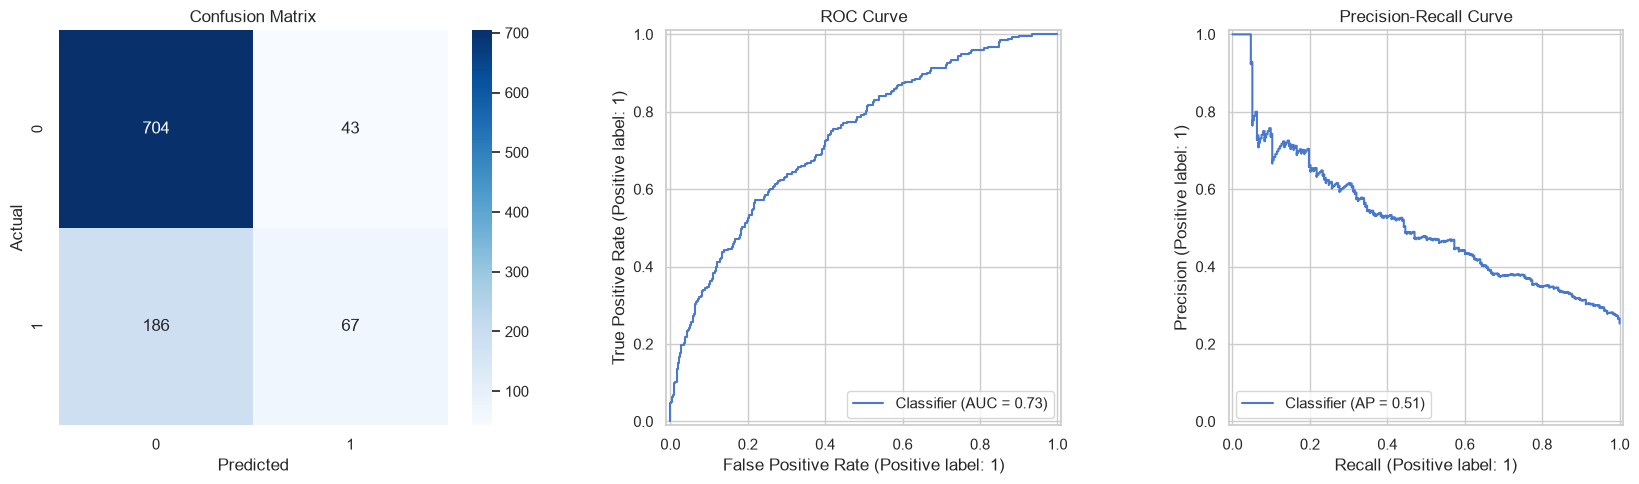

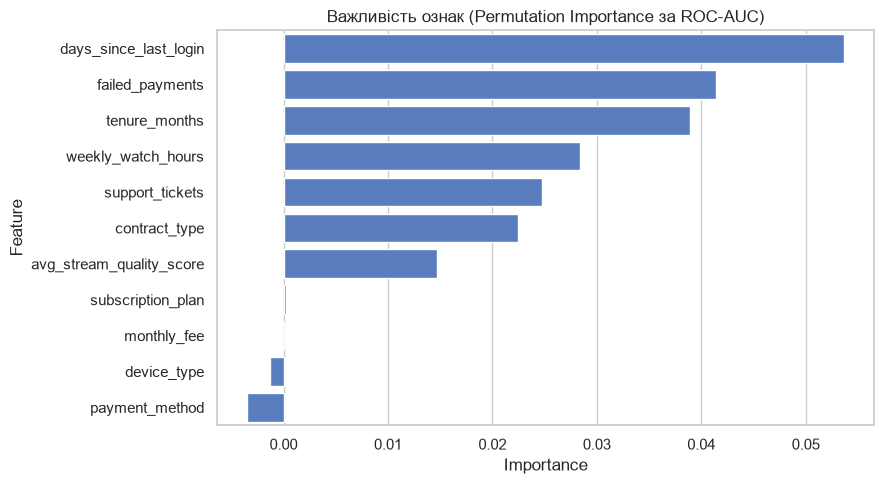

In [19]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print(f'Test ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}')
print(f'Test PR-AUC:  {average_precision_score(y_test, y_proba):.4f}\n')
print('Classification Report:\n', classification_report(y_test, y_pred))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[1].set_title('ROC Curve')

PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[2])
axes[2].set_title('Precision-Recall Curve')

plt.tight_layout()
plt.show()

perm_imp = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, scoring='roc_auc')
imp_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': perm_imp.importances_mean
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(data=imp_df, x='Importance', y='Feature')
plt.title('Важливість ознак (Permutation Importance за ROC-AUC)')
plt.tight_layout()
plt.show()

In [20]:
test_results = df.loc[X_test.index, ['user_id', 'subscription_plan', 'contract_type', 'weekly_watch_hours', 'failed_payments']].copy()
test_results['churn_probability'] = np.round(y_proba, 4)

high_risk_users = test_results[test_results['churn_probability'] >= 0.65].sort_values(by='churn_probability', ascending=False)
print(f'Виявлено користувачів групи високого ризику: {len(high_risk_users)} з {len(test_results)}')
high_risk_users.head(10)

Виявлено користувачів групи високого ризику: 33 з 1000


,user_id,subscription_plan,contract_type,weekly_watch_hours,failed_payments,churn_probability
4096,SP_104096,Standard,Monthly,NaN,0,0.8177
189,SP_100189,Basic,Monthly,3.0,0,0.8076
598,SP_100598,Premium,Monthly,13.3,0,0.7986
192,SP_100192,Basic,Monthly,4.0,1,0.7494
430,SP_100430,Premium,Monthly,2.1,2,0.7485
1184,SP_101184,Basic,Monthly,13.5,2,0.7410
4388,SP_104388,Standard,Monthly,12.5,2,0.7343
3473,SP_103473,Basic,Monthly,6.2,1,0.7320
3915,SP_103915,Basic,Monthly,4.0,1,0.7178
2903,SP_102903,Premium,Monthly,2.6,2,0.7170
